In [44]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
import operator

In [45]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [46]:
llm = ChatOpenAI(
    model = "openai/gpt-oss-20b",
    api_key = os.getenv("GROK_API_KEY"),
    base_url = "https://api.groq.com/openai/v1",
)

In [ ]:
class EvaluationSchema(BaseModel):
    feedback : str = Field(description = "Detailed feedback for the essay")
    score : int = Field(description = "Score out of 10", ge = 0, le = 10)

In [ ]:
structured_model = llm.with_structured_output(EvaluationSchema)

In [49]:
essay = """
Artificial Intelligence (AI) is transforming the way people live, work, and communicate. From virtual assistants to self-driving cars, AI has become an important part of modern society. It enables machines to perform tasks that traditionally require human intelligence.

One of the major benefits of AI is increased productivity. Businesses use AI to automate repetitive tasks, analyze large amounts of data, and make better decisions. In healthcare, AI can help doctors detect diseases and improve patient care. In education, AI-powered tools provide personalized learning experiences.

However, AI also presents several challenges. Automation may replace certain jobs, creating uncertainty for workers. Additionally, concerns about data privacy, biased algorithms, and the misuse of AI technologies are increasing. Therefore, AI must be developed and used responsibly.

In conclusion, Artificial Intelligence offers significant opportunities to improve society, but its challenges cannot be ignored. By promoting responsible development and ensuring appropriate regulations, society can maximize the benefits of AI while minimizing its risks.
"""

In [50]:
prompt = f"Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}"
structured_model.invoke(prompt)


EvaludationSchema(feedback='The essay is clear and well‑structured, with a logical progression from benefits to challenges and a concise conclusion. The language is generally fluent, but a few areas could be polished: reduce redundancy (e.g., “AI has become an important part of modern society” and “AI is transforming the way people live, work, and communicate” convey similar ideas), vary sentence openings to avoid repetition, and tighten phrasing such as “detect diseases and improve patient care” to “detect diseases and enhance patient care.” Adding a brief example in each section would strengthen the argument and give the reader concrete insights. Overall, the essay demonstrates good command of English with minor room for refinement.\n', score=8)

In [51]:
class UPSCState(TypedDict):
    essay : str
    language_feedback : str
    analysis_feedback : str
    clarity_feedback : str
    overall_feedback : str
    individual_scores : Annotated[list[int], operator.add]
    avg_score : float

In [52]:
def evaluate_language(state : UPSCState) -> UPSCState:
    prompt = f"Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}"
    output = structured_model.invoke(prompt)
    return {
        "language_feedback" : output.feedback,
        "individual_scores" : [output.score]
    }

In [53]:
def evaluate_analysis(state : UPSCState) -> UPSCState:
    prompt = f"Evaluate the depth of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}"
    output = structured_model.invoke(prompt)
    return {
        "analysis_feedback" : output.feedback,
        "individual_scores" : [output.score]
    }

In [54]:
def evaluate_thought(state : UPSCState) -> UPSCState:
    prompt = f"Evaluate the clarity of though following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}"
    output = structured_model.invoke(prompt)
    return {
        "clarity_feedback" : output.feedback,
        "individual_scores" : [output.score]
    }

In [55]:
def final_evaluation(state : UPSCState) -> UPSCState:
    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'
    overall_feedback = llm.invoke(prompt).content

    avg_score = sum(state["individual_scores"]) / len(state["individual_scores"])

    return {
        "overall_feedback" : overall_feedback,
        "avg_score" : avg_score
    }

In [56]:
graph = StateGraph(UPSCState)

graph.add_node("evaluate_language", evaluate_language)
graph.add_node("evaluate_analysis", evaluate_analysis)
graph.add_node("evaluate_thought", evaluate_thought)
graph.add_node("final_evaluation", final_evaluation)

In [57]:
# edges
graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought')

graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_thought', 'final_evaluation')

graph.add_edge('final_evaluation', END)

In [58]:
workflow = graph.compile()

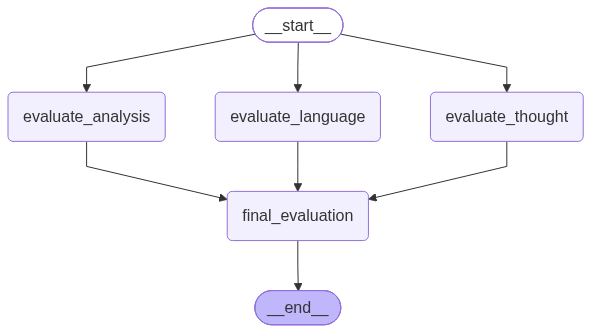

In [59]:
workflow

In [60]:
initial_state = {
    "essay" : essay
}

workflow.invoke(initial_state)

{'essay': '\nArtificial Intelligence (AI) is transforming the way people live, work, and communicate. From virtual assistants to self-driving cars, AI has become an important part of modern society. It enables machines to perform tasks that traditionally require human intelligence.\n\nOne of the major benefits of AI is increased productivity. Businesses use AI to automate repetitive tasks, analyze large amounts of data, and make better decisions. In healthcare, AI can help doctors detect diseases and improve patient care. In education, AI-powered tools provide personalized learning experiences.\n\nHowever, AI also presents several challenges. Automation may replace certain jobs, creating uncertainty for workers. Additionally, concerns about data privacy, biased algorithms, and the misuse of AI technologies are increasing. Therefore, AI must be developed and used responsibly.\n\nIn conclusion, Artificial Intelligence offers significant opportunities to improve society, but its challenge